<a href="https://colab.research.google.com/github/halomohammed/Ml-assignment1/blob/main/MiniBatch_Momentum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files
uploaded = files.upload()


Saving Position_Salaries.csv.csv to Position_Salaries.csv.csv


In [3]:
import pandas as pd

df = pd.read_csv("Position_Salaries.csv.csv")

df.head()


,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


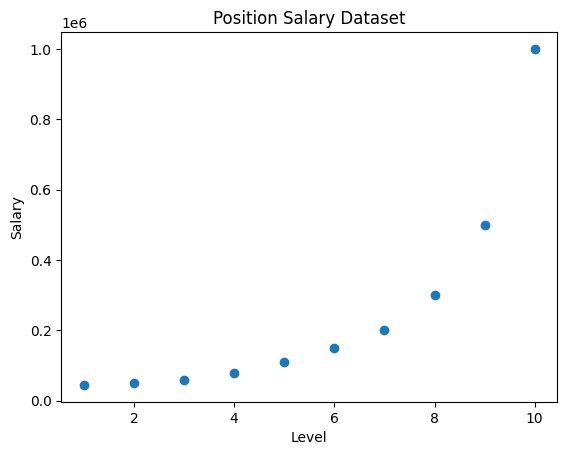

In [4]:
import matplotlib.pyplot as plt

X = df["Level"]
y = df["Salary"]

plt.scatter(X, y)
plt.xlabel("Level")
plt.ylabel("Salary")
plt.title("Position Salary Dataset")
plt.show()


In [5]:
import numpy as np

X = df["Level"].values
y = df["Salary"].values

X_poly = np.column_stack((X, X**2))

X_poly[:5]


array([[ 1,  1],
       [ 2,  4],
       [ 3,  9],
       [ 4, 16],
       [ 5, 25]])

In [7]:
w = np.zeros(2)
b = 0

lr = 0.000001

epochs = 500
batch_size = 3

vw = np.zeros(2)
vb = 0

momentum = 0.9

losses = []

n = len(X_poly)

for epoch in range(epochs):

    for i in range(0, n, batch_size):

        X_batch = X_poly[i:i+batch_size]
        y_batch = y[i:i+batch_size]

        y_pred = np.dot(X_batch, w) + b

        error = y_batch - y_pred

        dw = (-2 / len(X_batch)) * np.dot(X_batch.T, error)
        db = (-2 / len(X_batch)) * np.sum(error)

        vw = momentum * vw - lr * dw
        vb = momentum * vb - lr * db

        w = w + vw
        b = b + vb

    total_pred = np.dot(X_poly, w) + b

    loss = np.mean((y - total_pred) ** 2)

    losses.append(loss)

print("Training Finished")


Training Finished


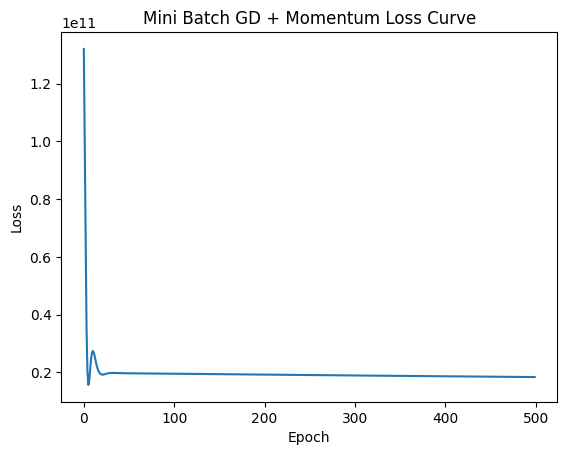

In [8]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Mini Batch GD + Momentum Loss Curve")
plt.show()
